# Chapter 12 · Multilevel Monte Carlo: interactive demos

Companion to Chapter 12 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/12-multilevel.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the model is geometric Brownian motion with the course's test case ($S_0=K=100$, $T=1$, $r=1\%$,
$y=2\%$, $\sigma=20\%$ unless you change it), discretised by the Euler or the Milstein scheme. Level $\ell$ uses
$2^\ell$ time steps, and a sample of the correction $Y_\ell=P_\ell-P_{\ell-1}$ uses one Brownian path for both the
fine and the coarse member. Costs are counted in time steps.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Dropdown

from mfe230d import bs
from mfe230d.multilevel import (GBMLevels, asian_call_payoff, call_payoff, coupled_sum, digital_payoff,
                                level_statistics, mlmc, single_term, standard_mc_cost)
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

def payoff_for(name, r=0.01, T=1.0, K=100.0):
    D = np.exp(-r * T)
    return {"call": call_payoff(K, D), "digital": digital_payoff(K, D), "Asian call": asian_call_payoff(K, D)}[name]

def exact_price(name, sigma):
    if name == "call":
        return bs.call(100.0, 100.0, 1.0, 0.01, 0.02, sigma)
    if name == "digital":
        return bs.digital_call(100.0, 100.0, 1.0, 0.01, 0.02, sigma)
    return None    # the continuously averaged Asian call has no closed form

## 1. How fast do the corrections shrink?

For each level the cell draws coupled fine and coarse paths and reports the variance $V_\ell$ and the mean of the
correction $Y_\ell$, next to the variance of the payoff itself. Proposition 12.4 predicts $V_\ell\propto2^{-\ell}$
for Euler and $\propto4^{-\ell}$ for Milstein with a Lipschitz payoff (the call), and a slower decay for the digital,
whose payoff jumps at the strike. The means decay like $2^{-\ell}$: the weak order. The Asian call averages the path
with the trapezoidal rule on each grid.

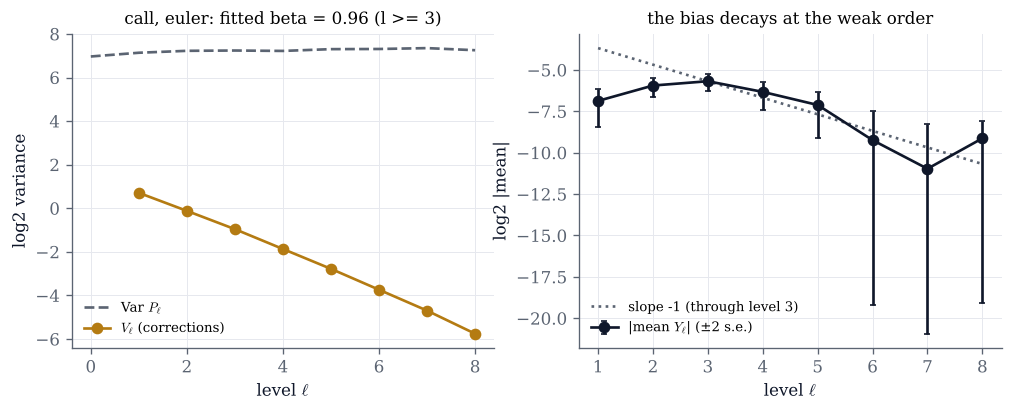

In [2]:
def levels(payoff="call", scheme="euler", sigma=0.2, L=8, n_top=400_000, seed=1):
    f = payoff_for(payoff)
    sampler = GBMLevels(payoff=f, sigma=sigma, scheme=scheme)
    ls = np.arange(L + 1)
    n = [max(int(n_top / 2**l), 20_000) for l in ls]
    st = level_statistics(sampler, ls, n, seed=seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(ls, np.log2(st["var_P"]), color=GREY, ls="--", label="Var $P_\\ell$")
    ax.plot(ls[1:], np.log2(st["var"][1:]), color=COBALT if scheme == "milstein" else GOLD, marker="o",
            label="$V_\\ell$ (corrections)")
    slope = -np.polyfit(ls[3:], np.log2(st["var"][3:]), 1)[0]
    ax.set(xlabel="level $\\ell$", ylabel="log2 variance", title=f"{payoff}, {scheme}: fitted beta = {slope:.2f} (l >= 3)")
    ax.legend(fontsize=8)
    m = np.abs(st["mean"][1:])
    se = np.sqrt(st["var"][1:] / st["n"][1:])
    ax2.errorbar(ls[1:], np.log2(m), yerr=[np.log2(m) - np.log2(np.maximum(m - 2 * se, m * 1e-3)),
                 np.log2(m + 2 * se) - np.log2(m)], color=INK, marker="o", capsize=2, label="|mean $Y_\\ell$| (±2 s.e.)")
    ax2.plot(ls[1:], np.log2(m[2]) - (ls[1:] - 3), color=GREY, ls=":", label="slope -1 (through level 3)")
    ax2.set(xlabel="level $\\ell$", ylabel="log2 |mean|", title="the bias decays at the weak order")
    ax2.legend(fontsize=8)
    plt.show()

levels()

In [3]:
# Explore: switch to Milstein; then try the digital with both schemes; raise sigma to see the rates settle later.
interact(levels,
         payoff=Dropdown(options=["call", "digital", "Asian call"], value="call", description="payoff"),
         scheme=Dropdown(options=["euler", "milstein"], value="euler", description="scheme"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         L=IntSlider(value=8, min=3, max=10, continuous_update=False, description="levels L"),
         n_top=FloatLogSlider(value=4e5, base=10, min=4, max=6, step=0.25, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 2. The adaptive algorithm

Given a target root-mean-square error $\varepsilon$, the algorithm of Section 12.4 estimates the variances $V_\ell$,
sets the sample sizes $n_\ell\propto\sqrt{V_\ell/\tau_\ell}$ (Proposition 12.2), and adds levels until the estimated
remaining bias (Lemma 12.8) is below $\varepsilon/\sqrt2$. The left panel shows how the work $n_\ell\tau_\ell$ is
spread over the levels; the right panel compares the total cost with plain Monte Carlo on the same finest level.
The error of one run is random: its root-mean-square size over many runs is about $\varepsilon$, so errors of one or
two times $\varepsilon$ are normal (change the seed).

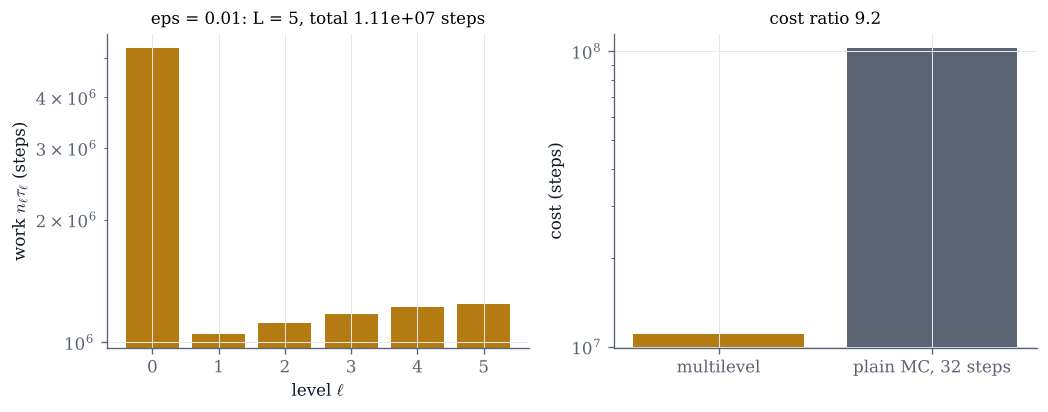

estimate 7.37068 ± 0.00707 (s.e.), exact 7.36429, error +0.00639
n_l = [5278968, 349546, 185825, 97448, 50840, 25836]


In [4]:
def adaptive(payoff="call", scheme="euler", log10_eps=-2.0, seed=1):
    eps = 10.0**log10_eps
    f = payoff_for(payoff)
    sampler = GBMLevels(payoff=f, scheme=scheme)
    beta = 1.0 if scheme == "euler" else 2.0
    R = mlmc(sampler, eps, alpha=1.0, beta=beta, N0=1000, seed=seed)
    L = R["L"]
    tau = np.array([sampler.cost(l) for l in range(L + 1)])
    Sf = sampler(L, 20_000, np.random.default_rng(seed + 1))[0]          # Var P_L for the plain estimator
    mc = standard_mc_cost(Sf.var(ddof=1), L, eps)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.bar(np.arange(L + 1), R["N"] * tau, color=COBALT if scheme == "milstein" else GOLD)
    ax.set(yscale="log", xlabel="level $\\ell$", ylabel="work $n_\\ell \\tau_\\ell$ (steps)",
           title=f"eps = {eps:.3g}: L = {L}, total {R['cost']:.3g} steps")
    ax2.bar([0, 1], [R["cost"], mc], color=[COBALT if scheme == "milstein" else GOLD, GREY])
    ax2.set_xticks([0, 1], ["multilevel", f"plain MC, {2**L} steps"])
    ax2.set(yscale="log", ylabel="cost (steps)", title=f"cost ratio {mc / R['cost']:.1f}")
    plt.show()
    exact = exact_price(payoff, 0.2)
    line = f"estimate {R['estimate']:.5f} ± {R['se']:.5f} (s.e.)"
    if exact is not None:
        line += f", exact {exact:.5f}, error {R['estimate'] - exact:+.5f}"
    print(line)
    print("n_l =", R["N"].tolist())

adaptive()

In [5]:
# Explore: halve eps a few times with each scheme and watch eps^2 x cost: flat for Milstein, slowly growing for Euler.
interact(adaptive,
         payoff=Dropdown(options=["call", "Asian call"], value="call", description="payoff"),
         scheme=Dropdown(options=["euler", "milstein"], value="euler", description="scheme"),
         log10_eps=FloatSlider(value=-2.0, min=-2.6, max=-1.0, step=0.1, continuous_update=False, description="log10 ε"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Unbiased randomised estimators

The single-term estimator of Rhee and Glynn draws a level $J$ with $P(J=j)\propto2^{-rj}$ and returns
$Y_J/p_J$ with $p_j=P(J=j)$; the coupled sum adds all the corrections up to $J$ along one path (Remark 12.11). Both are unbiased
when the variance is finite. Proposition 12.10 says that a finite variance needs $r<\beta$ and a finite expected cost
needs $r>\gamma=1$: for Milstein ($\beta=2$) any $r$ in between works, for Euler ($\beta=\gamma=1$) none does. The
left panel shows the running estimate with its $\pm2$ standard-error band, the right panel the running average cost
per sample. To keep the demo fast, $J$ is capped at level 14 (`max_level=14`): the capped estimators are unbiased for
the level-14 price, whose bias is negligible here, and the cap hides the infinite mean cost when $r\le1$ only
partially (watch the cost panel).

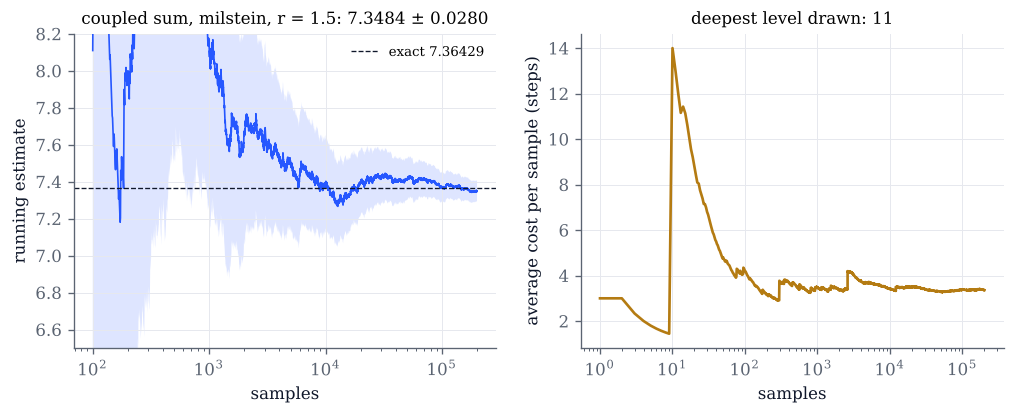

In [6]:
def randomised(scheme="milstein", r=1.5, estimator="coupled sum", n=200_000, seed=5):
    sampler = GBMLevels(scheme=scheme)
    fn = coupled_sum if estimator == "coupled sum" else single_term
    R = fn(sampler, int(n), r, seed=seed, max_level=14)
    Z = R["Z"]
    k = np.arange(1, Z.size + 1)
    run = np.cumsum(Z) / k
    sd = np.sqrt(np.maximum(np.cumsum(Z * Z) / k - run**2, 0.0) / k)
    lv = R["levels"]
    cost = np.where(lv == 0, 1.0, 3.0 * 2.0 ** (lv - 1)) if fn is single_term else 2.0 ** (lv + 1) - 1
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    sel = k >= 100
    ax.plot(k[sel], run[sel], color=COBALT, lw=1)
    ax.fill_between(k[sel], (run - 2 * sd)[sel], (run + 2 * sd)[sel], color=COBALT, alpha=0.15, lw=0)
    ax.axhline(bs.call(**bs.TEST_CASE), color=INK, ls="--", lw=0.8, label="exact 7.36429")
    ax.set(xscale="log", xlabel="samples", ylabel="running estimate", ylim=(6.5, 8.2),
           title=f"{estimator}, {scheme}, r = {r}: {R['mean']:.4f} ± {R['se']:.4f}")
    ax.legend(fontsize=8)
    ax2.plot(k, np.cumsum(cost) / k, color=GOLD)
    ax2.set(xscale="log", xlabel="samples", ylabel="average cost per sample (steps)",
            title=f"deepest level drawn: {lv.max()}")
    plt.show()

randomised()

In [7]:
# Explore: with Euler, try r = 0.8 (finite variance, infinite mean cost) and r = 1.2 (finite mean cost, infinite variance).
interact(randomised,
         scheme=Dropdown(options=["euler", "milstein"], value="milstein", description="scheme"),
         r=FloatSlider(value=1.5, min=0.6, max=2.4, step=0.05, continuous_update=False, description="rate r"),
         estimator=Dropdown(options=["coupled sum", "single term"], value="coupled sum", description="estimator"),
         n=FloatLogSlider(value=2e5, base=10, min=4, max=6, step=0.25, continuous_update=False, description="samples"),
         seed=IntSlider(value=5, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, compare the call and the Asian call with Euler. Why does the Asian start with a faster decay that slows
  down at fine levels? (Hint: two errors compete, the quadrature of the average and the strong error of the scheme.)
- In section 1, set $\sigma=0.6$ with Milstein. At which level does the variance start to fall by four per level?
- In section 2, find the accuracy at which multilevel Euler is ten times cheaper than plain Monte Carlo for the
  call. How does that change with Milstein?
- In section 3, with Milstein, push $r$ towards $2$ and towards $1$ and watch which panel misbehaves first. Then
  switch to Euler: can you find any $r$ for which both panels settle down?